# 2 - Exploratory Data Analysis (EDA)

## Hotel Booking Cancellation Prediction

This notebook is prepared for the EDA stage of the IT3051 FDM Mini Project. The current completed section is **Member 2 - Stay & Reservation Analysis**. Placeholder sections are included for Member 1 and Member 3 so their analyses can be added later.

## EDA Objective

The purpose of EDA is to explore the Hotel Booking dataset to identify cancellation-related patterns, feature distributions, unusual observations, and potential feature-engineering opportunities. Findings from this stage will guide preprocessing, feature engineering, feature selection, and future modelling decisions.

## Import Libraries and Load Dataset

In [53]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 120)
sns.set_theme(style='whitegrid', palette='Set2')

DATA_PATH = Path('../data/raw/hotel_booking.csv')
FIGURE_DIR = Path('Figures/stay_reservation')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## Helper Functions

In [54]:
def cancellation_rate_table(data, column):
    summary = (
        data.groupby(column, dropna=False)['is_canceled']
        .agg(total_bookings='count', canceled_bookings='sum', cancellation_rate='mean')
        .reset_index()
    )
    summary['cancellation_rate'] = (summary['cancellation_rate'] * 100).round(2)
    return summary.sort_values('cancellation_rate', ascending=False)

def save_current_figure(filename):
    path = FIGURE_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved figure: {path}')

## Overall Target Distribution

This gives context for Member 2 target comparisons. A cancellation rate of the full dataset is useful as a baseline.

In [55]:
target_summary = df['is_canceled'].value_counts().sort_index().reset_index()
target_summary.columns = ['is_canceled', 'count']
target_summary['meaning'] = target_summary['is_canceled'].map({0: 'Not canceled', 1: 'Canceled'})
target_summary['percentage'] = (target_summary['count'] / len(df) * 100).round(2)
target_summary

,is_canceled,count,meaning,percentage
0,0,75166,Not canceled,62.96
1,1,44224,Canceled,37.04


## Member 1 - Booking & Customer Behaviour Analysis (Placeholder)

This section is reserved for Member 1. Suggested variables include lead time, previous cancellations, previous bookings not canceled, repeated guest, booking changes, days in waiting list, special requests, customer type, and related target comparisons.

## Member 2 - Stay & Reservation Analysis

This section analyses stay and reservation attributes assigned to Member 2:

- Hotel type
- Arrival period
- Weekend-night stays
- Week-night stays
- Adults, children, babies
- Meal
- Reserved room type
- Parking requirements
- Related target comparisons
- Outliers or unusual observations
- Feature-engineering opportunities such as `total_stay` and `total_guests`

### 2.1 Hotel Type Distribution and Cancellation Rate

In [56]:
hotel_counts = df['hotel'].value_counts().reset_index()
hotel_counts.columns = ['hotel', 'count']
hotel_counts['percentage'] = (hotel_counts['count'] / len(df) * 100).round(2)
hotel_counts

,hotel,count,percentage
0,City Hotel,79330,66.45
1,Resort Hotel,40060,33.55


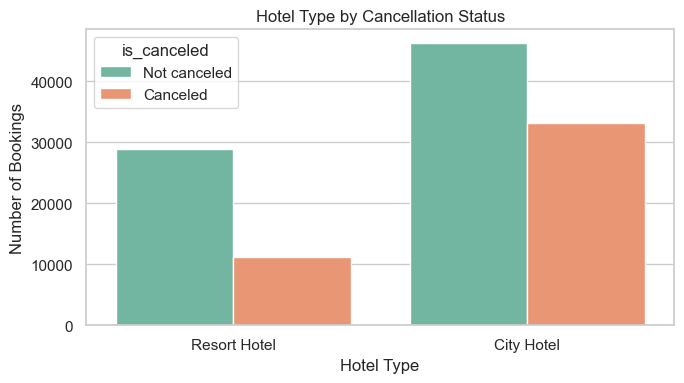

Saved figure: Figures\stay_reservation\hotel_type_by_cancellation.png


In [57]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='hotel', hue='is_canceled')
plt.title('Hotel Type by Cancellation Status')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('hotel_type_by_cancellation.png')

In [58]:
hotel_cancel_rate = cancellation_rate_table(df, 'hotel')
hotel_cancel_rate

,hotel,total_bookings,canceled_bookings,cancellation_rate
0,City Hotel,79330,33102,41.73
1,Resort Hotel,40060,11122,27.76


In [59]:
highest_hotel = hotel_cancel_rate.iloc[0]
lowest_hotel = hotel_cancel_rate.iloc[-1]
rate_gap = highest_hotel['cancellation_rate'] - lowest_hotel['cancellation_rate']
print(f"Observed result: {highest_hotel['hotel']} has the higher cancellation rate "
      f"({highest_hotel['cancellation_rate']:.2f}%) compared with {lowest_hotel['hotel']} "
      f"({lowest_hotel['cancellation_rate']:.2f}%).")
print(f"Difference: approximately {rate_gap:.2f} percentage points.")

Observed result: City Hotel has the higher cancellation rate (41.73%) compared with Resort Hotel (27.76%).
Difference: approximately 13.97 percentage points.


**Finding:** The hotel-type comparison should be interpreted using the observed cancellation-rate table above. The hotel category with the higher cancellation rate may capture different booking behaviour, customer segments, or reservation conditions. This variable should be retained as a categorical predictor and encoded during preprocessing.

### 2.2 Arrival Period Analysis

This section focuses on arrival month and arrival year because they are the most meaningful period-level variables for identifying broad seasonal and yearly cancellation patterns. Week number and day of month are not visualized here to avoid adding less interpretable plots without a clear analytical purpose.

In [60]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
arrival_month_summary = cancellation_rate_table(df, 'arrival_date_month')
arrival_month_summary['arrival_date_month'] = pd.Categorical(arrival_month_summary['arrival_date_month'], categories=month_order, ordered=True)
arrival_month_summary.sort_values('arrival_date_month')

,arrival_date_month,total_bookings,canceled_bookings,cancellation_rate
4,January,5929,1807,30.48
3,February,8068,2696,33.42
7,March,9794,3149,32.15
0,April,11089,4524,40.80
8,May,11791,4677,39.67
6,June,10939,4535,41.46
5,July,12661,4742,37.45
1,August,13877,5239,37.75
11,September,10508,4116,39.17
10,October,11160,4246,38.05


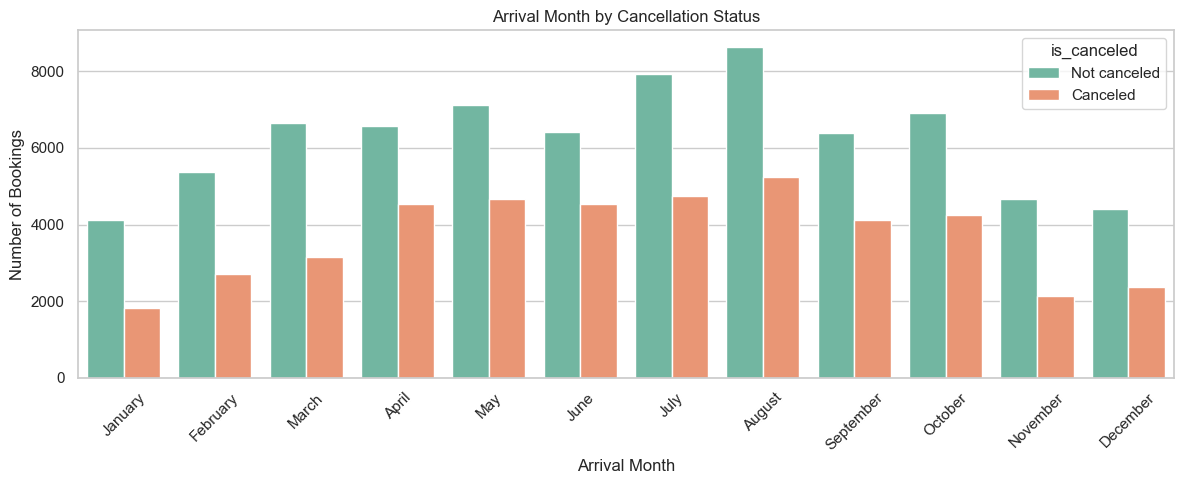

Saved figure: Figures\stay_reservation\arrival_month_by_cancellation.png


In [61]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='arrival_date_month', hue='is_canceled', order=month_order)
plt.title('Arrival Month by Cancellation Status')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('arrival_month_by_cancellation.png')

In [62]:
arrival_year_summary = cancellation_rate_table(df, 'arrival_date_year')
arrival_year_summary

,arrival_date_year,total_bookings,canceled_bookings,cancellation_rate
2,2017,40687,15745,38.70
0,2015,21996,8142,37.02
1,2016,56707,20337,35.86


In [63]:
arrival_month_rates = arrival_month_summary.sort_values('cancellation_rate', ascending=False)
arrival_year_rates = arrival_year_summary.sort_values('cancellation_rate', ascending=False)
print(f"Highest cancellation month: {arrival_month_rates.iloc[0]['arrival_date_month']} "
      f"({arrival_month_rates.iloc[0]['cancellation_rate']:.2f}%).")
print(f"Lowest cancellation month: {arrival_month_rates.iloc[-1]['arrival_date_month']} "
      f"({arrival_month_rates.iloc[-1]['cancellation_rate']:.2f}%).")
print(f"Highest cancellation year: {arrival_year_rates.iloc[0]['arrival_date_year']} "
      f"({arrival_year_rates.iloc[0]['cancellation_rate']:.2f}%).")

Highest cancellation month: June (41.46%).
Lowest cancellation month: January (30.48%).
Highest cancellation year: 2017.0 (38.70%).


**Finding:** Arrival month and year show period-level differences in cancellation rates. These observed differences suggest that arrival timing may contain useful seasonal or yearly information. During preprocessing/feature engineering, month and year should be handled as time-related features rather than ignored.

### 2.3 Stay Duration Analysis

This section examines weekend-night stays and week-night stays. It also proposes `total_stay` as a future engineered feature.

In [64]:
stay_columns = ['stays_in_weekend_nights', 'stays_in_week_nights']
df[stay_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
stays_in_weekend_nights,119390.0,0.93,1.00,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.0,1.0,2.0,3.0,50.0


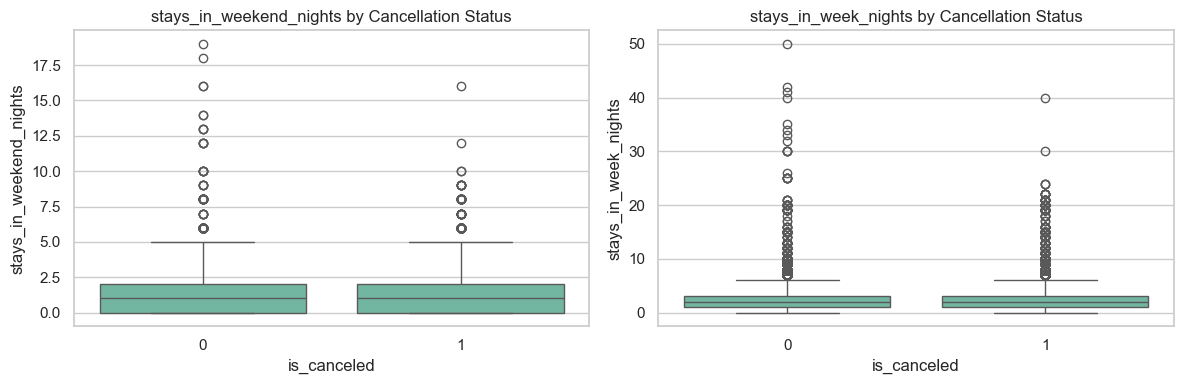

Saved figure: Figures\stay_reservation\stay_nights_boxplots.png


In [65]:
plt.figure(figsize=(12, 4))
for i, column in enumerate(stay_columns, start=1):
    plt.subplot(1, 2, i)
    sns.boxplot(data=df, x='is_canceled', y=column)
    plt.title(f'{column} by Cancellation Status')
    plt.xlabel('is_canceled')
    plt.ylabel(column)
save_current_figure('stay_nights_boxplots.png')

In [66]:
df_member2 = df.copy()
df_member2['total_stay'] = df_member2['stays_in_weekend_nights'] + df_member2['stays_in_week_nights']
total_stay_summary = df_member2['total_stay'].describe().to_frame('total_stay').T.round(2)
zero_night_count = int((df_member2['total_stay'] == 0).sum())
total_stay_summary['zero_night_bookings'] = zero_night_count
total_stay_summary

,count,mean,std,min,25%,50%,75%,max,zero_night_bookings
total_stay,119390.0,3.43,2.56,0.0,2.0,3.0,4.0,69.0,715


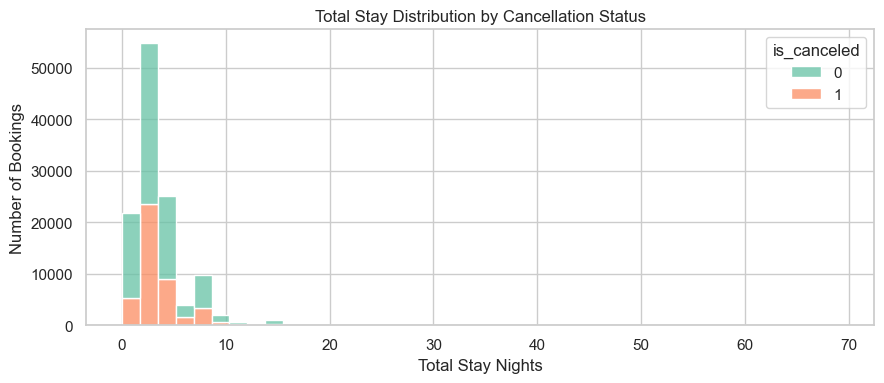

Saved figure: Figures\stay_reservation\total_stay_distribution.png


In [67]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df_member2, x='total_stay', hue='is_canceled', bins=40, kde=False, multiple='stack')
plt.title('Total Stay Distribution by Cancellation Status')
plt.xlabel('Total Stay Nights')
plt.ylabel('Number of Bookings')
save_current_figure('total_stay_distribution.png')

In [68]:
df_member2['stay_length_group'] = pd.cut(
    df_member2['total_stay'],
    bins=[-1, 0, 2, 7, np.inf],
    labels=['Zero-night stay', 'Short stay (1-2 nights)', 'Medium stay (3-7 nights)', 'Long stay (8+ nights)']
)
stay_length_cancel_rate = cancellation_rate_table(df_member2, 'stay_length_group')
stay_length_cancel_rate.sort_values('stay_length_group')

,stay_length_group,total_bookings,canceled_bookings,cancellation_rate
0,Zero-night stay,715,35,4.90
1,Short stay (1-2 nights),48663,17434,35.83
2,Medium stay (3-7 nights),64755,24876,38.42
3,Long stay (8+ nights),5257,1879,35.74


In [69]:
stay_rates = stay_length_cancel_rate.sort_values('cancellation_rate', ascending=False)
print(f"Highest cancellation stay group: {stay_rates.iloc[0]['stay_length_group']} "
      f"({stay_rates.iloc[0]['cancellation_rate']:.2f}%).")
print(f"Lowest cancellation stay group: {stay_rates.iloc[-1]['stay_length_group']} "
      f"({stay_rates.iloc[-1]['cancellation_rate']:.2f}%).")

Highest cancellation stay group: Medium stay (3-7 nights) (38.42%).
Lowest cancellation stay group: Zero-night stay (4.90%).


**Finding:** The binned stay-length comparison provides a clearer target comparison for `total_stay`. If cancellation rates differ across stay-length groups, `total_stay` may be useful as an engineered feature. Zero-night and very long-stay records should still be investigated during preprocessing rather than removed during EDA.

### 2.4 Guest Composition Analysis

This section analyses adults, children, and babies. It also proposes `total_guests` as a possible engineered feature.

In [70]:
guest_columns = ['adults', 'children', 'babies']
df[guest_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
adults,119390.0,1.86,0.58,0.0,2.0,2.0,2.0,55.0
children,119386.0,0.10,0.40,0.0,0.0,0.0,0.0,10.0
babies,119390.0,0.01,0.10,0.0,0.0,0.0,0.0,10.0


In [71]:
# EDA-only temporary treatment: children has 4 missing values.
# For exploratory calculation of total_guests, missing children values are temporarily treated as 0.
# Final missing-value treatment must be justified and performed during preprocessing.
df_member2['children'] = df_member2['children'].fillna(0)
df_member2['total_guests'] = df_member2['adults'] + df_member2['children'] + df_member2['babies']
guest_summary = df_member2[['adults', 'children', 'babies', 'total_guests']].describe().T.round(2)
guest_summary['zero_guest_bookings'] = [
    int((df_member2['adults'] == 0).sum()),
    int((df_member2['children'] == 0).sum()),
    int((df_member2['babies'] == 0).sum()),
    int((df_member2['total_guests'] == 0).sum())
]
guest_summary

,count,mean,std,min,25%,50%,75%,max,zero_guest_bookings
adults,119390.0,1.86,0.58,0.0,2.0,2.0,2.0,55.0,403
children,119390.0,0.10,0.40,0.0,0.0,0.0,0.0,10.0,110800
babies,119390.0,0.01,0.10,0.0,0.0,0.0,0.0,10.0,118473
total_guests,119390.0,1.97,0.72,0.0,2.0,2.0,2.0,55.0,180


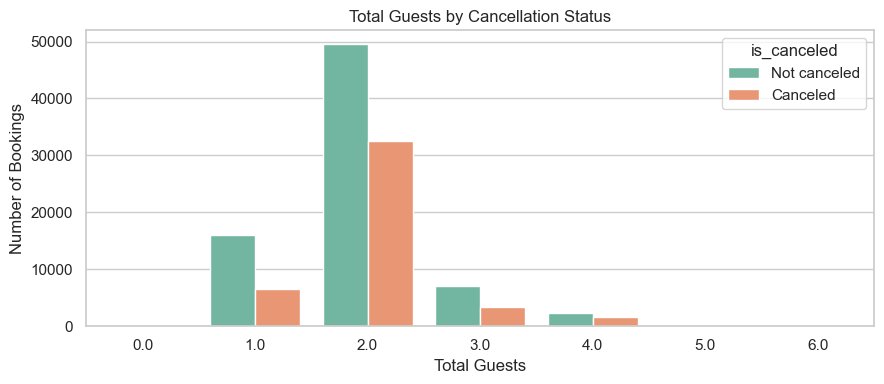

Saved figure: Figures\stay_reservation\total_guests_by_cancellation.png


In [72]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df_member2[df_member2['total_guests'] <= 6], x='total_guests', hue='is_canceled')
plt.title('Total Guests by Cancellation Status')
plt.xlabel('Total Guests')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('total_guests_by_cancellation.png')

In [73]:
df_member2['has_children'] = np.where(df_member2['children'] > 0, 'Has children', 'No children')
df_member2['has_babies'] = np.where(df_member2['babies'] > 0, 'Has babies', 'No babies')
children_babies_cancel_rate = pd.concat(
    [
        cancellation_rate_table(df_member2, 'has_children').assign(feature='children_presence'),
        cancellation_rate_table(df_member2, 'has_babies').assign(feature='babies_presence'),
    ],
    ignore_index=True
)
children_babies_cancel_rate

,has_children,total_bookings,canceled_bookings,cancellation_rate,feature,has_babies
0,No children,110800,41098,37.09,children_presence,NaN
1,Has children,8590,3126,36.39,children_presence,NaN
2,NaN,118473,44057,37.19,babies_presence,No babies
3,NaN,917,167,18.21,babies_presence,Has babies


In [74]:
children_rates = cancellation_rate_table(df_member2, 'has_children')
babies_rates = cancellation_rate_table(df_member2, 'has_babies')
print('Children presence cancellation rates:')
print(children_rates[['has_children', 'cancellation_rate']].to_string(index=False))
print('\nBabies presence cancellation rates:')
print(babies_rates[['has_babies', 'cancellation_rate']].to_string(index=False))

Children presence cancellation rates:
has_children  cancellation_rate
 No children              37.09
Has children              36.39

Babies presence cancellation rates:
has_babies  cancellation_rate
 No babies              37.19
Has babies              18.21


**Finding:** `total_guests` is a useful feature-engineering opportunity, but individual guest-composition indicators are also informative. Comparing bookings with and without children/babies gives a clearer view of how family-related guest composition relates to cancellation. Records with zero total guests should be treated as unusual and investigated during preprocessing.

### 2.5 Meal Type Analysis

In [75]:
df['meal'].value_counts(dropna=False).to_frame('count')

,count
meal,
BB,92310
HB,14463
SC,10650
Undefined,1169
FB,798


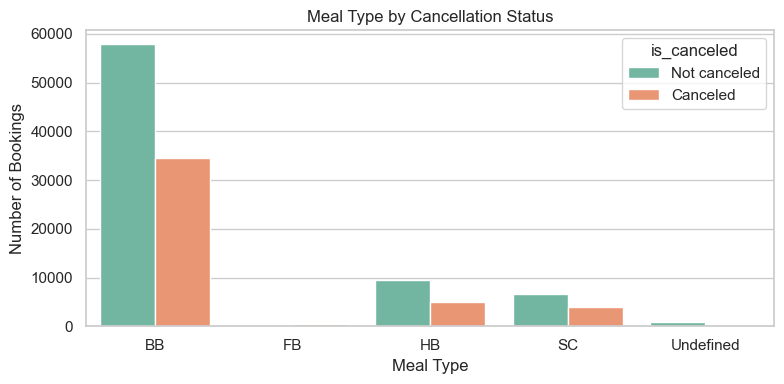

Saved figure: Figures\stay_reservation\meal_type_by_cancellation.png


In [76]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='meal', hue='is_canceled')
plt.title('Meal Type by Cancellation Status')
plt.xlabel('Meal Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('meal_type_by_cancellation.png')

In [77]:
cancellation_rate_table(df, 'meal')

,meal,total_bookings,canceled_bookings,cancellation_rate
1,FB,798,478,59.90
0,BB,92310,34510,37.38
3,SC,10650,3966,37.24
2,HB,14463,4984,34.46
4,Undefined,1169,286,24.47


**Finding:** Meal is a categorical feature and should be encoded during preprocessing. Undefined or rare categories should be reviewed before encoding.

### 2.6 Reserved Room Type Analysis

In [78]:
df['reserved_room_type'].value_counts(dropna=False).to_frame('count')

,count
reserved_room_type,
A,85994
D,19201
E,6535
F,2897
G,2094
B,1118
C,932
H,601
P,12


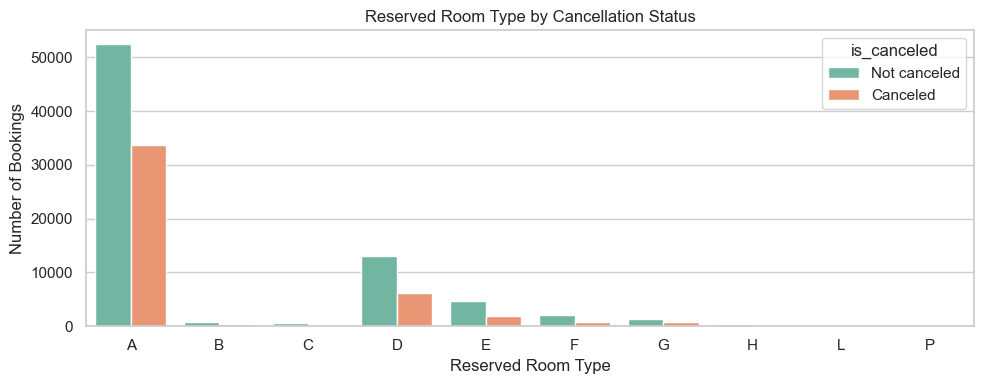

Saved figure: Figures\stay_reservation\reserved_room_type_by_cancellation.png


In [79]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='reserved_room_type', hue='is_canceled', order=sorted(df['reserved_room_type'].unique()))
plt.title('Reserved Room Type by Cancellation Status')
plt.xlabel('Reserved Room Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('reserved_room_type_by_cancellation.png')

In [80]:
cancellation_rate_table(df, 'reserved_room_type')

,reserved_room_type,total_bookings,canceled_bookings,cancellation_rate
9,P,12,12,100.00
7,H,601,245,40.77
0,A,85994,33630,39.11
6,G,2094,763,36.44
8,L,6,2,33.33
2,C,932,308,33.05
1,B,1118,368,32.92
3,D,19201,6102,31.78
5,F,2897,880,30.38
4,E,6535,1914,29.29


**Finding:** Reserved room type may reflect customer preference and booking conditions. It should be retained as a categorical feature, while rare room categories may require careful encoding.

### 2.7 Parking Requirement Analysis

In [81]:
df['required_car_parking_spaces'].value_counts(dropna=False).sort_index().to_frame('count')

,count
required_car_parking_spaces,
0,111974
1,7383
2,28
3,3
8,2


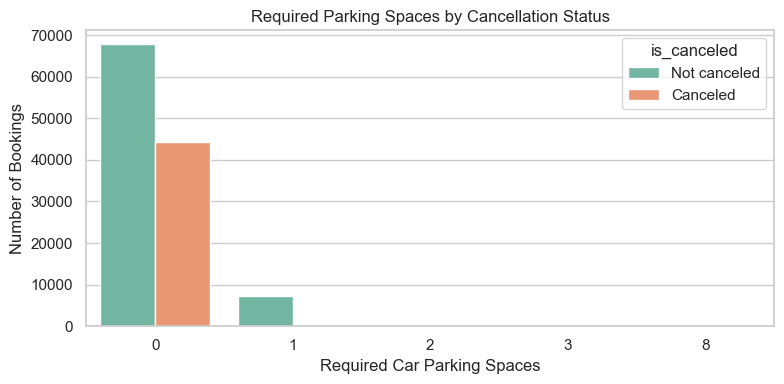

Saved figure: Figures\stay_reservation\parking_spaces_by_cancellation.png


In [82]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='required_car_parking_spaces', hue='is_canceled')
plt.title('Required Parking Spaces by Cancellation Status')
plt.xlabel('Required Car Parking Spaces')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('parking_spaces_by_cancellation.png')

In [83]:
parking_cancel_rate = cancellation_rate_table(df, 'required_car_parking_spaces')
parking_cancel_rate

,required_car_parking_spaces,total_bookings,canceled_bookings,cancellation_rate
0,0,111974,44224,39.49
1,1,7383,0,0.00
2,2,28,0,0.00
3,3,3,0,0.00
4,8,2,0,0.00


In [84]:
no_parking_rate = parking_cancel_rate.loc[parking_cancel_rate['required_car_parking_spaces'].eq(0), 'cancellation_rate'].iloc[0]
parking_requested = df.assign(parking_requested=np.where(df['required_car_parking_spaces'] > 0, 'Parking requested', 'No parking requested'))
parking_request_rate = cancellation_rate_table(parking_requested, 'parking_requested')
print(parking_request_rate.to_string(index=False))
print(f"Cancellation rate for zero parking spaces: {no_parking_rate:.2f}%")

   parking_requested  total_bookings  canceled_bookings  cancellation_rate
No parking requested          111974              44224              39.49
   Parking requested            7416                  0               0.00
Cancellation rate for zero parking spaces: 39.49%


**Finding:** Parking should be interpreted from the observed cancellation-rate table above. If bookings with requested parking show a lower cancellation rate than bookings with no parking request, this supports the idea that parking requests may indicate stronger booking intention. The variable is discrete numerical and may be useful without complex transformation, while rare high values should be reviewed.

### 2.8 Member 2 Outlier and Unusual Observation Summary

In [85]:
member2_unusual = pd.DataFrame([
    {'check': 'Zero total stay nights', 'count': int((df_member2['total_stay'] == 0).sum())},
    {'check': 'Very long stays above 30 nights', 'count': int((df_member2['total_stay'] > 30).sum())},
    {'check': 'Missing children values', 'count': int(df['children'].isna().sum())},
    {'check': 'Zero total guests', 'count': int((df_member2['total_guests'] == 0).sum())},
    {'check': 'Bookings with more than 6 guests', 'count': int((df_member2['total_guests'] > 6).sum())},
    {'check': 'Undefined meal values', 'count': int((df['meal'] == 'Undefined').sum())},
    {'check': 'Parking spaces greater than 2', 'count': int((df['required_car_parking_spaces'] > 2).sum())},
])
member2_unusual

,check,count
0,Zero total stay nights,715
1,Very long stays above 30 nights,24
2,Missing children values,4
3,Zero total guests,180
4,Bookings with more than 6 guests,16
5,Undefined meal values,1169
6,Parking spaces greater than 2,5


### 2.9 Member 2 Preprocessing and Feature-Engineering Implications

- Encode categorical variables: `hotel`, `arrival_date_month`, `meal`, and `reserved_room_type`.
- Consider engineering `total_stay = stays_in_weekend_nights + stays_in_week_nights`.
- Consider engineering `total_guests = adults + children + babies`.
- Investigate zero-night bookings and zero-guest bookings before cleaning.
- Handle the small number of missing `children` values during preprocessing.
- Review rare categories in `meal` and `reserved_room_type` before encoding.
- Keep `required_car_parking_spaces` as a useful discrete numerical feature, while reviewing rare high values.

## Member 3 - Commercial & Distribution Analysis (Placeholder)

This section is reserved for Member 3. Suggested variables include market segment, distribution channel, deposit type, agent/company, ADR, country, assigned room type, correlations, high-cardinality variables, missing-value patterns, and data-leakage variables such as `reservation_status` and `reservation_status_date`.

## Overall EDA Conclusion and Recommendations (To Be Completed After All Members Finish)

This section should combine Member 1, Member 2, and Member 3 findings into one final EDA conclusion and preprocessing/feature-engineering recommendation section.